# EDA on the cleaned tabular features

This notebook explores `data/processed/tabular_clean`: fraud rate per
year, feature distributions, redundancy, and changes across years. The goal is to inform
the feature-engineering decisions (scaling, dropping redundant features, YoY
deltas, dimensionality reduction).

Run `python src/clean_tabular.py` first so that `data/processed/` exists.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30, "display.width", 200)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
KEYS = ["nodeID", "Year", "Label"]

clean = pd.read_parquet(ROOT / "data" / "processed" / "tabular_clean")
log = pd.read_csv(ROOT / "data" / "processed" / "cleaning_log.csv")
splits = pd.read_csv(ROOT / "data" / "splits" / "temporal_splits.csv")

kept = log.loc[log["action"] == "kept", "column"].tolist()
groups = log.set_index("column")["group"]
features = [c for c in kept if c not in KEYS]
numeric_features = [c for c in features if c != "IndustryCodeC"]
monetary_groups = {"balance sheet", "income statement", "cash flow (direct)", "cash flow (indirect)"}

print("clean:", clean.shape, "(one row per company-year — use this for anything pooled across years)")

clean: (33664, 669) (one row per company-year — use this for anything pooled across years)


In [ ]:

fold_view = clean.merge(splits[["nodeID", "Year", "split", "role"]], on=["nodeID", "Year"], how="left")
assert fold_view["split"].notna().all(), "some company-years are missing a fold assignment"

print("fold_view:", fold_view.shape, "(one row per company-year per fold — fold/role analysis only)")
fold_view[["split", "role"]].value_counts().sort_index()

fold_view: (105453, 671) (one row per company-year per fold — fold/role analysis only)


split  role 
0      test      3815
       train    15679
1      test      4269
       train    19494
2      test      4769
       train    23763
3      test      5132
       train    28532
Name: count, dtype: int64

## 1. Fraud rate per year

Each fold in `temporal_splits.csv` is a rolling-origin split (train window grows, test
year moves forward one year at a time)

- fold 0: trains on 2014-2018 and tests on 2019
- fold 1: trains 2014-2019 and tests 2020
- fold 2: trains 2014-2020, test 2021
- fold 3: train 2014-2021,test 2022

In [3]:
yearly = clean.groupby("Year").agg(companies=("nodeID", "size"), fraud=("Label", "sum"))
yearly["fraud_rate"] = yearly["fraud"] / yearly["companies"]
yearly.round(4)

,companies,fraud,fraud_rate
Year,,,
2014,2631,95,0.0361
2015,2824,134,0.0475
2016,3125,173,0.0554
2017,3503,205,0.0585
2018,3596,225,0.0626
2019,3815,214,0.0561
2020,4269,207,0.0485
2021,4769,183,0.0384
2022,5132,123,0.0240


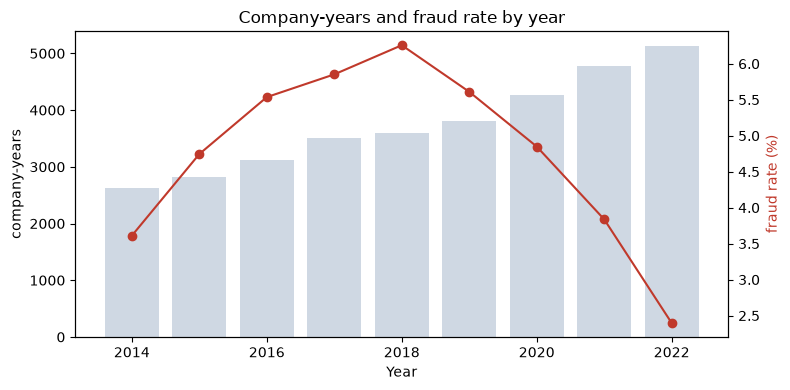

In [4]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(yearly.index, yearly["companies"], color="#cfd8e3", label="company-years")
ax1.set_ylabel("company-years")
ax1.set_xlabel("Year")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["fraud_rate"] * 100, color="#c0392b", marker="o")
ax2.set_ylabel("fraud rate (%)", color="#c0392b")
ax1.set_title("Company-years and fraud rate by year")
fig.tight_layout()
plt.show()

Fraud rate by fold and role — this is the imbalance the model step actually has to handle, in both train and test.

In [5]:
fold_summary = fold_view.groupby(["split", "role"]).agg(n=("Label", "size"), fraud=("Label", "sum"))
fold_summary["fraud_rate"] = (fold_summary["fraud"] / fold_summary["n"]).round(4)
fold_summary

n  fraud  fraud_rate
split role                           
0     test    3815    214      0.0561
      train  15679    832      0.0531
1     test    4269    207      0.0485
      train  19494   1046      0.0537
2     test    4769    183      0.0384
      train  23763   1253      0.0527
3     test    5132    123      0.0240
      train  28532   1436      0.0503

## 2. Missingness overview

Builds on `check_cleaning.ipynb` section 6 (which lists the worst individual columns) by
looking at missingness by feature group and across all incomplete columns.

In [6]:
kept_log = log[log["action"] == "kept"]
group_missing = (kept_log.groupby("group")["missing_clean"].mean() * 100).sort_values(ascending=False)
group_missing.round(2)

group
ratio / other           4.50
cash flow (indirect)    0.01
balance sheet           0.00
cash flow (direct)      0.00
categorical             0.00
income statement        0.00
Name: missing_clean, dtype: float64

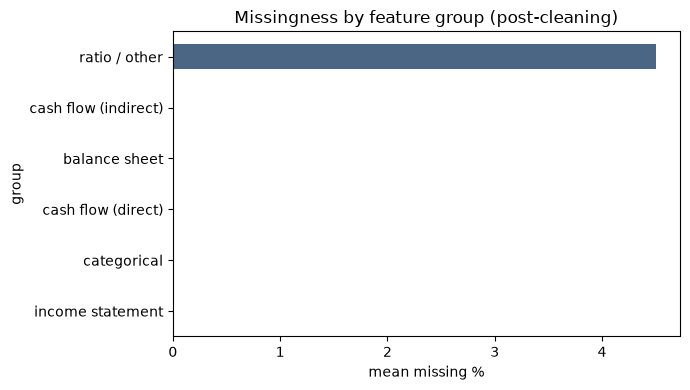

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
group_missing.plot.barh(ax=ax, color="#4b6584")
ax.invert_yaxis()
ax.set_xlabel("mean missing %")
ax.set_title("Missingness by feature group (post-cleaning)")
fig.tight_layout()
plt.show()

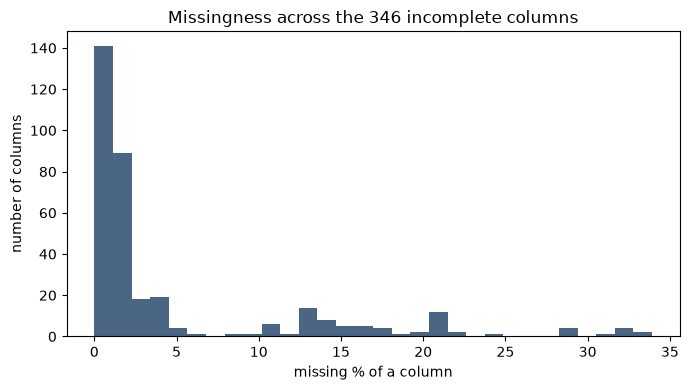

In [8]:
incomplete = kept_log[kept_log["missing_clean"] > 0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(incomplete["missing_clean"] * 100, bins=30, color="#4b6584")
ax.set_xlabel("missing % of a column")
ax.set_ylabel("number of columns")
ax.set_title(f"Missingness across the {len(incomplete)} incomplete columns")
fig.tight_layout()
plt.show()

## 3. Feature distributions by fraud label

Ranking features by how well they separate fraud from non-fraud is a modelling decision,
so it is computed on fold 3's **training** rows only (2014-2021) — the largest training
window, and it never touches the final 2022 test rows. The plots below then show the
full dataset for context.

In [ ]:
train_ref = fold_view[(fold_view["split"] == 3) & (fold_view["role"] == "train")]
fraud_rows = train_ref[train_ref["Label"] == 1]
clean_rows = train_ref[train_ref["Label"] == 0]

def standardized_gap(col):
    a, b = fraud_rows[col].dropna(), clean_rows[col].dropna() #a: feature's values for fraud companies. b: for non fraud companies
    if len(a) < 5 or len(b) < 5:
        return np.nan
    pooled_std = np.sqrt((a.var() + b.var()) / 2)
    if not pooled_std > 0:
        return np.nan
    return abs(a.mean() - b.mean()) / pooled_std

gaps = pd.Series({c: standardized_gap(c) for c in numeric_features}, name="standardized_gap").dropna()
gaps_df = gaps.to_frame().join(groups.rename("group")).reset_index(names="column")
gaps_df.sort_values("standardized_gap", ascending=False).head(15)

,column,standardized_gap,group
576,F091602A,0.618561,ratio / other
575,F091502A,0.607565,ratio / other
551,F091601A,0.583553,ratio / other
643,KZ,0.582134,ratio / other
563,F090302B,0.572165,ratio / other
535,F090104B,0.568127,ratio / other
533,F090102B,0.567128,ratio / other
564,F090402B,0.566257,ratio / other
537,F090202B,0.558910,ratio / other
569,F090902B,0.558374,ratio / other


In [10]:
top_features = (
    gaps_df.sort_values("standardized_gap", ascending=False)
    .groupby("group")
    .head(2)["column"]
    .tolist()
)
top_features

['F091602A',
 'F091502A',
 'B003000000',
 'B004000000',
 'D000101000',
 'C001020000',
 'A001101000',
 'C003006000',
 'A001212000',
 'D000204000']

/var/folders/by/5gqwqr8977bcfm7sxdcb10w40000gn/T/ipykernel_5439/3947089528.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([y0, y1], vert=False, tick_labels=["not fraud", "fraud"], showfliers=False)
/var/folders/by/5gqwqr8977bcfm7sxdcb10w40000gn/T/ipykernel_5439/3947089528.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([y0, y1], vert=False, tick_labels=["not fraud", "fraud"], showfliers=False)
/var/folders/by/5gqwqr8977bcfm7sxdcb10w40000gn/T/ipykernel_5439/3947089528.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([y0, y1], vert=False, tick_labels=["not fraud", "fraud"], showfliers=False)
/var/folders/by/

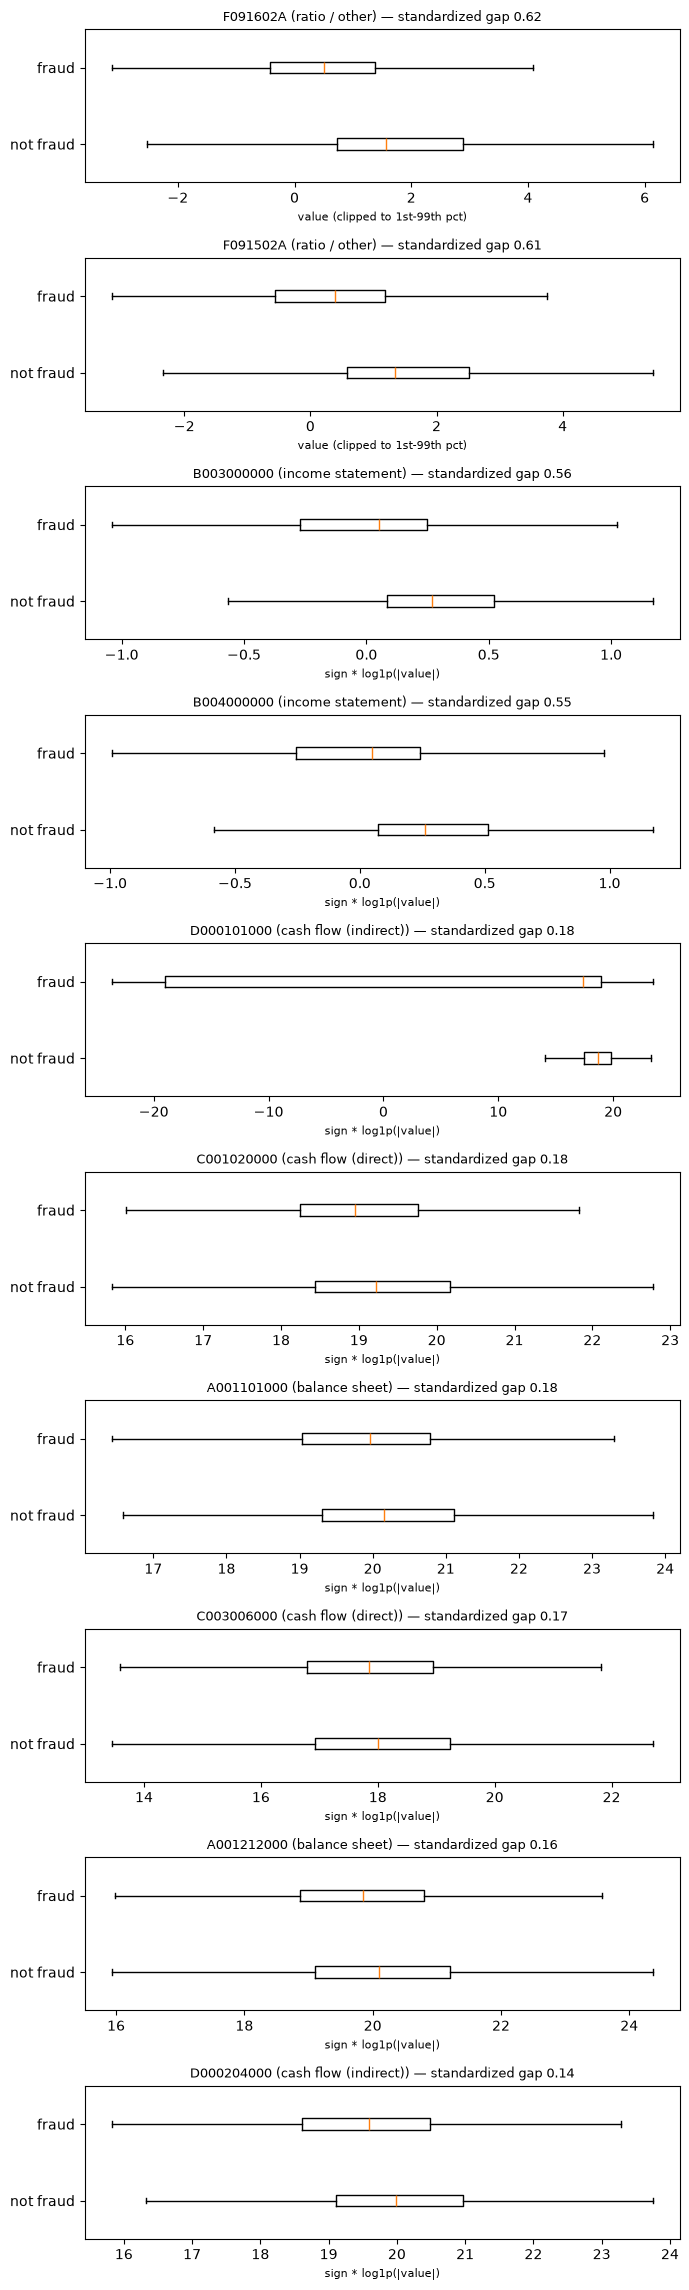

In [11]:
fig, axes = plt.subplots(len(top_features), 1, figsize=(7, 2.3 * len(top_features)))
for ax, col in zip(axes, top_features):
    vals = clean[["Label", col]].dropna()
    y0, y1 = vals.loc[vals["Label"] == 0, col], vals.loc[vals["Label"] == 1, col]
    if groups[col] in monetary_groups:
        y0, y1 = np.sign(y0) * np.log1p(np.abs(y0)), np.sign(y1) * np.log1p(np.abs(y1))
        xlabel = "sign * log1p(|value|)"
    else:
        lo, hi = vals[col].quantile([0.01, 0.99])
        y0, y1 = y0.clip(lo, hi), y1.clip(lo, hi)
        xlabel = "value (clipped to 1st-99th pct)"
    ax.boxplot([y0, y1], vert=False, tick_labels=["not fraud", "fraud"], showfliers=False)
    ax.set_title(f"{col} ({groups[col]}) — standardized gap {gaps[col]:.2f}", fontsize=9)
    ax.set_xlabel(xlabel, fontsize=8)
fig.tight_layout()
plt.show()

## 4. Redundancy check


Groups larger than 25 columns are reduced to their top 25 by standardized gap (section 3) so the heatmaps stay readable.

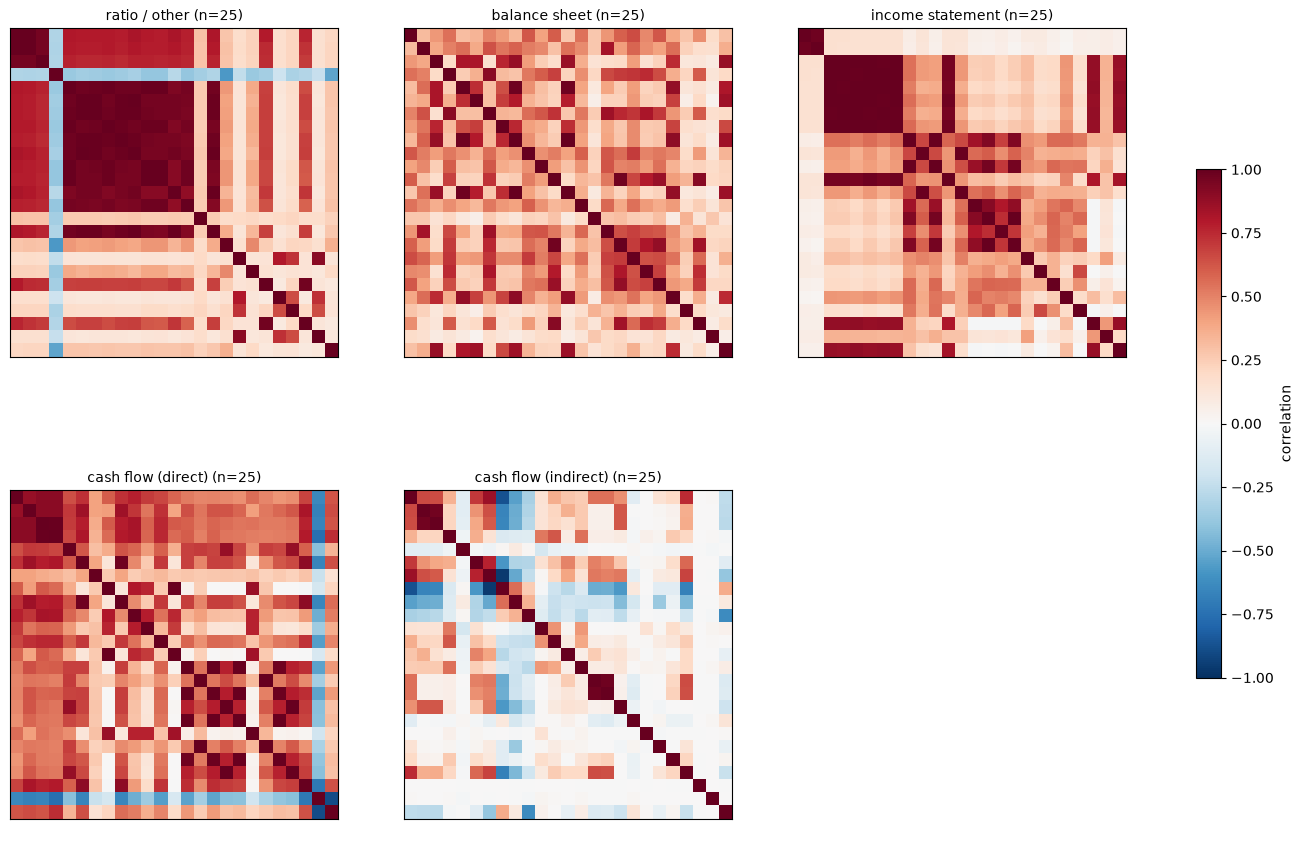

In [12]:
sample_cols = {}
for g in [g for g in groups.unique() if g != "categorical"]:
    cols_g = [c for c in numeric_features if groups[c] == g]
    if len(cols_g) > 25:
        ranked = gaps_df[gaps_df["group"] == g].sort_values("standardized_gap", ascending=False)
        cols_g = ranked["column"].head(25).tolist()
    sample_cols[g] = cols_g

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
im = None
for ax, (g, cols_g) in zip(axes.ravel(), sample_cols.items()):
    corr = clean[cols_g].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{g} (n={len(cols_g)})", fontsize=10)
for ax in axes.ravel()[len(sample_cols):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.6, label="correlation")
plt.show()

In [13]:
high_corr_pairs = []
for g, cols_g in sample_cols.items():
    corr = clean[cols_g].corr().abs()
    for i, a in enumerate(cols_g):
        for b in cols_g[i + 1:]:
            r = corr.loc[a, b]
            if r > 0.95:
                high_corr_pairs.append((g, a, b, round(float(r), 3)))

high_corr = pd.DataFrame(high_corr_pairs, columns=["group", "feature_a", "feature_b", "corr"])
high_corr = high_corr.sort_values("corr", ascending=False)
print(f"{len(high_corr)} pairs with |corr| > 0.95 among the sampled columns")
high_corr.head(20)

90 pairs with |corr| > 0.95 among the sampled columns


,group,feature_a,feature_b,corr
67,income statement,B001000000,B001300000,1.000
85,cash flow (direct),C003008000,C003003000,0.999
41,ratio / other,F020108,F020109,0.999
53,income statement,B002000000,B001000000,0.998
55,income statement,B002000000,B001300000,0.998
52,income statement,B002000000,B002000101,0.997
75,income statement,B001101000,B001201000,0.997
79,cash flow (direct),C002200000,C002007000,0.996
59,income statement,B006000000,B006000101,0.996
48,balance sheet,A003000000,A003100000,0.996


## 5. Changes across years

Mean of each top separating feature by year, split by fraud label, to check for concept
drift or scale shifts across the 2014-2022 span.

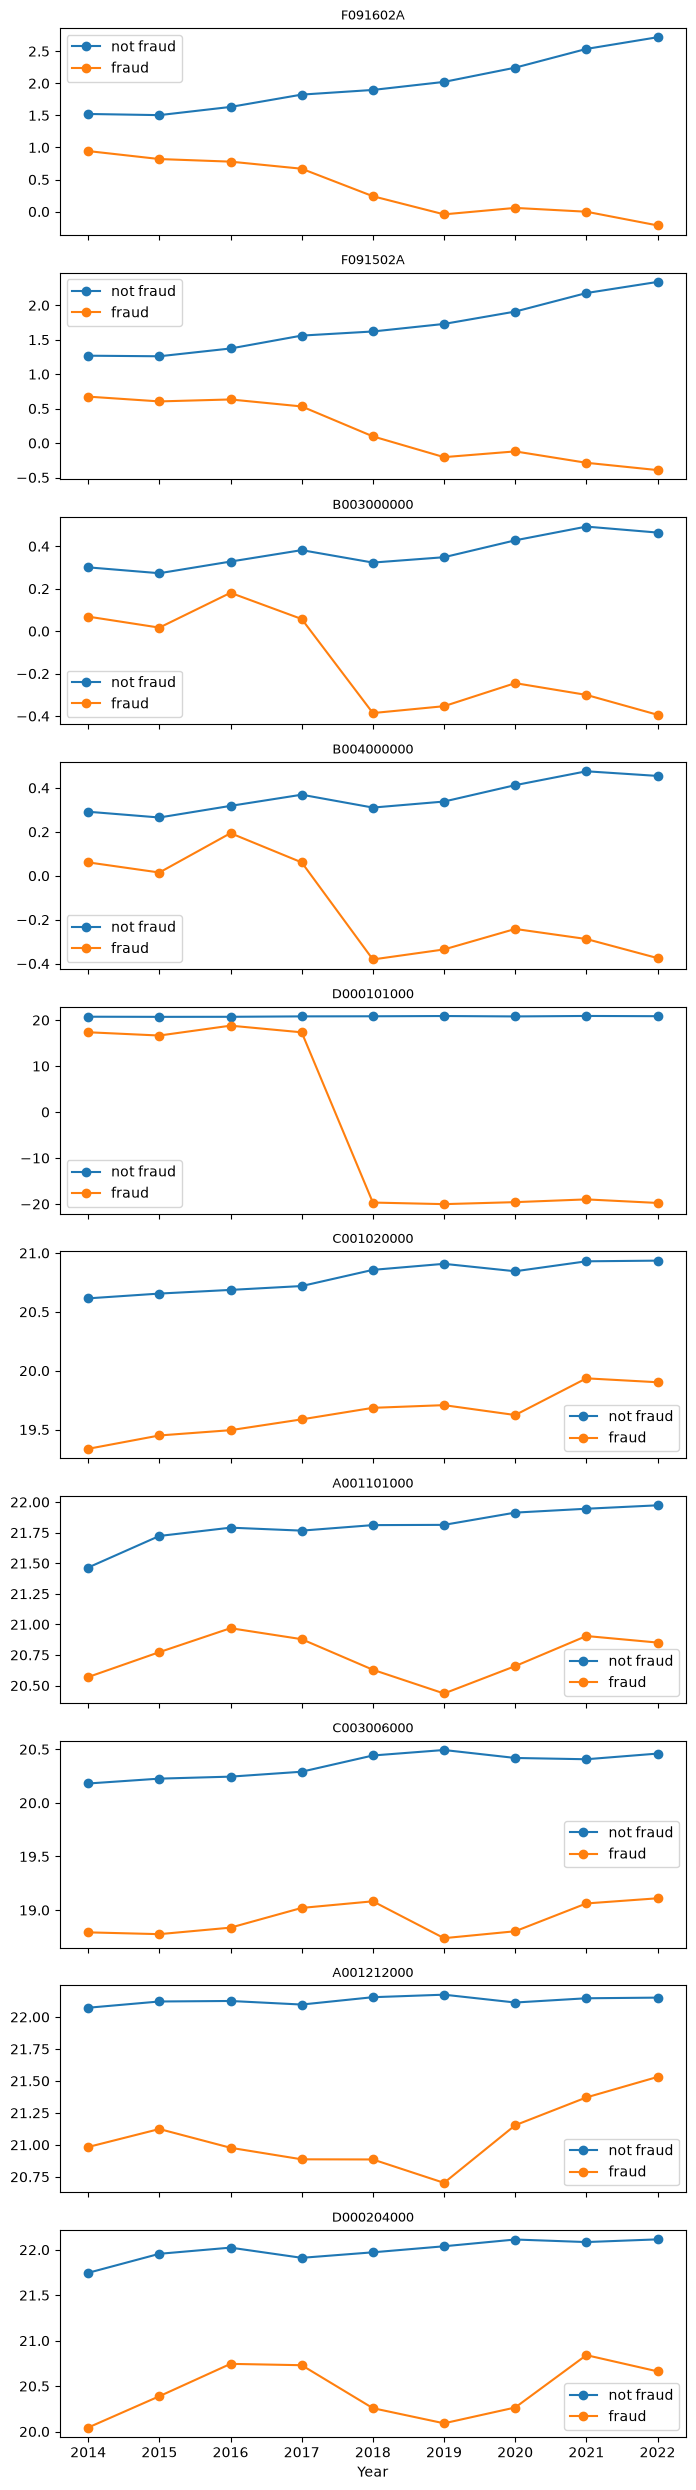

In [14]:
fig, axes = plt.subplots(len(top_features), 1, figsize=(7, 2.5 * len(top_features)), sharex=True)
for ax, col in zip(axes, top_features):
    yearly_mean = clean.groupby(["Year", "Label"])[col].mean().unstack()
    if groups[col] in monetary_groups:
        yearly_mean = np.sign(yearly_mean) * np.log1p(np.abs(yearly_mean))
    yearly_mean.columns = ["not fraud", "fraud"]
    yearly_mean.plot(ax=ax, marker="o")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
axes[-1].set_xlabel("Year")
fig.tight_layout()
plt.show()

## 6. Categorical / geographic

Fraud rate by industry, and whether fraud looks geographically concentrated.

In [15]:
industry = clean.groupby("IndustryCodeC").agg(n=("Label", "size"), fraud=("Label", "sum"))
industry["fraud_rate"] = industry["fraud"] / industry["n"]
print("By volume:")
display(industry.sort_values("n", ascending=False).head(10))
print("By fraud rate (industries with at least 30 company-years):")
display(industry[industry["n"] >= 30].sort_values("fraud_rate", ascending=False).head(10))

By volume:


,n,fraud,fraud_rate
IndustryCodeC,,,
C39,3306,166,0.050212
C26,2241,113,0.050424
C38,2130,107,0.050235
C35,2092,99,0.047323
C27,2018,76,0.037661
I65,1883,103,0.054700
C34,1248,45,0.036058
C36,1135,33,0.029075
K70,1117,35,0.031334


By fraud rate (industries with at least 30 company-years):


,n,fraud,fraud_rate
IndustryCodeC,,,
G60,30,4,0.133333
I64,462,59,0.127706
C41,171,21,0.122807
A04,74,9,0.121622
N77,347,34,0.097983
F51,689,64,0.092888
A01,141,13,0.092199
I63,140,12,0.085714
J69,110,9,0.081818


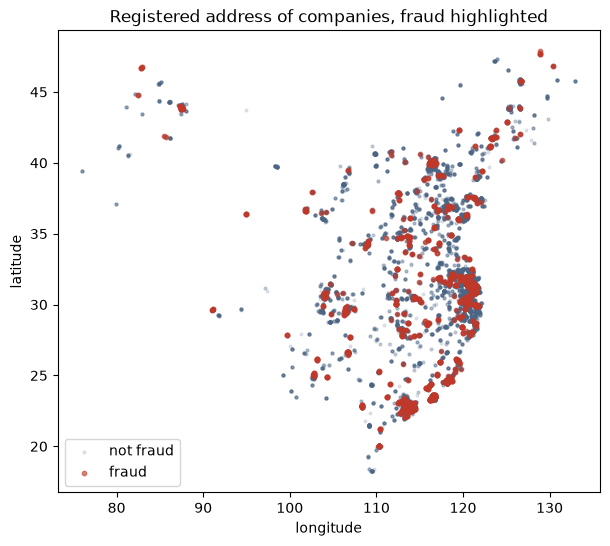

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
nf = clean[clean["Label"] == 0]
fr = clean[clean["Label"] == 1]
ax.scatter(nf["RegisterLongitude"], nf["RegisterLatitude"], s=4, alpha=0.15, color="#4b6584", label="not fraud")
ax.scatter(fr["RegisterLongitude"], fr["RegisterLatitude"], s=10, alpha=0.6, color="#c0392b", label="fraud")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Registered address of companies, fraud highlighted")
ax.legend()
plt.show()

## 7. Takeaways for feature engineering

- **Class imbalance is not constant across years.** Fraud rate runs 3.6% (2014) up to a
  peak of 6.3% (2018), then falls to 2.4% by 2022 — the final fold's test year is the
  *least* imbalanced of all. Loss reweighting in step 6 should not assume one fixed
  global ratio; check what each training fold's own imbalance looks like, since fold 3
  trains on a period averaging ~5.0% fraud but tests on a year at 2.4%.

- **Missingness is almost entirely in the "ratio / other" group** (4.5% mean missing per
  column) — balance sheet, income statement and cash flow columns are ~0% missing
  (expected, since `clean_tabular.py` already filled unreported statement items with 0).
  Imputation effort in feature engineering should concentrate on the ratio/other block.

- **The most class-separating features are concentrated in "ratio / other"** — several
  profitability/efficiency ratios (`F091602A`, `F091502A`, `F091601A`, `KZ`, the `F0901xx`/
  `F0903xx` series) plus two income-statement profit totals (`B003000000`, `B004000000`)
  dominate the standardized-gap ranking (computed on fold 3's training rows only). These
  are good candidates to prioritize if dimensionality reduction needs to pick a reduced
  set rather than run on all 666 columns.

- **Redundancy is real and worth trimming**: 90 pairs with |corr| > 0.95 even among just
  the top-25-per-group columns. It's concentrated in two places — (1) income statement
  profit variants that are near-identical restatements of the same figure
  (`B001000000`/`B001300000`/`B002000000`/`B002000101`/`B006000000`/`B006000101`), and
  (2) a handful of ratio/other pairs (`F020108`/`F020109`, `F090102B`/`F090104B`/
  `F090902B`). Feature engineering should drop down to one representative per cluster.

- **YoY deltas look worthwhile, not just levels.** For most top features the fraud vs.
  non-fraud gap widens over 2014-2022 rather than staying flat (e.g. `F091602A`,
  `F091502A` diverge further each year) — a static level understates how separable fraud
  becomes in later years. `B003000000`/`B004000000` show a sharper break around 2018-2019,
  where the fraud group drops hard into negative territory while non-fraud keeps rising —
  that regime shift is itself a signal worth preserving, not smoothing away.

- **One likely data artifact to check before use**: `D000101000` is flat around 17-20 for
  fraud companies through 2017, then jumps to a flat ~-20 for every year from 2018
  onward, with almost no year-to-year variance in either regime. A level that flat reads
  more like an encoding/sentinel artifact than real financial behaviour — worth checking
  the raw values and the feature's description before including it as-is.

- **`IndustryCodeC` carries real signal.** Fraud rate by industry ranges from ~3-6% in
  the highest-volume industries (C39, C26, C38, C35, C27, I65) up to 12-13% in smaller
  ones (G60, I64, C41, A04) — worth a proper categorical encoding (one-hot or
  frequency/target encoding) rather than dropping it.

- **Geography shows no obvious standalone signal.** Fraud points roughly track the
  general density of registered companies (clustered around 110-125°E, 20-35°N) rather
  than concentrating in any distinct sub-region — `RegisterLongitude`/`RegisterLatitude`
  are probably low priority for feature engineering on their own.